# Type I seesaw with two active and two sterile neutrinos

$$M=\begin{pmatrix}0 & m_D\\ m_D^T & M_R\end{pmatrix},\qquad m_D\in\mathbb{C}^{2\times2},\qquad U^TMU=\mathrm{diag}(m_1,m_2,m_3,m_4).$$

**Assumptions**

* $M_R=\mathrm{diag}(M_1,M_2)$ with $0<M_1<\dots$ (sterile basis choice, no loss of generality).
* Real case: all $m_{Dij}\in\mathbb{R}$.
* Complex case: $m_{Dij}=r_{ij}e^{i\phi_{ij}}$ with the phases of the first column removed by rephasing the active fields: $n(m-1)=2$ physical phases.

**Structure.** No massless state(s) and $k=m+\min(n,m)=4$ massive ones: 2 light ($\lambda<0$ in the real case, by Sylvester's law of inertia) and 2 heavy ($\lambda>0$). The characteristic polynomial is a **quartic**, the highest degree solvable in radicals. This is the last rung of the ladder where the direct method works; the notebook measures what the closed form costs.

In [1]:
import os
import sys

# Make the ``src`` package importable (the notebook lives in ``notebooks/``)
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

import numpy as np
import sympy as sp
from sympy import (symbols, solve, sin, cos, tan, sqrt, exp, I, pi, Matrix,
                   conjugate, factor, simplify, init_printing)

from src.seesaw import SymbolicSeesawTypeI
from src.matrix_utils import (symbolic_rotation_matrix, sin_cos_from_tan_fraction,
                              simplify_with_mass_ordering, seesaw_block_expansion,
                              takagi_factorization)
from src.symbolic_diagonalization import *

init_printing()
import time

## 1. Mass matrix and characteristic polynomial (real case)

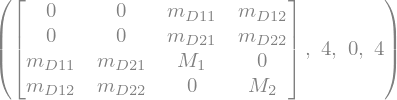

In [2]:
seesaw = SymbolicSeesawTypeI(n_generations=2, n_sterile=2, dirac='real', majorana_basis='diagonal')
mD = seesaw.m_D_sym
MR = seesaw.M_R_sym
mn = seesaw.masses
massive = list(seesaw.massive_masses)
zeros = [0]*seesaw.n_massless
Mnu = seesaw.full_mass_matrix_symbolic()
Mnu, Mnu.rank(), seesaw.n_massless, seesaw.n_massive

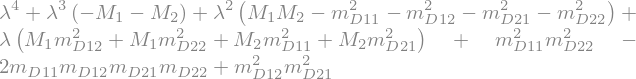

In [3]:
lamb = symbols('lambda', real=True)
charpoly = seesaw.reduced_charpoly(lamb=lamb)
charpoly.as_expr().collect(lamb)

## 2. Direct solution: Ferrari's method

With $\lambda=y-a/4$ the quartic becomes $y^4+py^2+qy+r=0$. If $\mu$ is the largest root of the resolvent cubic $\mu^3+p\mu^2+(p^2/4-r)\mu-q^2/8=0$ (three real roots, taken in trigonometric form), then

$$y=\tfrac12\left[s\sqrt{2\mu}\pm\sqrt{-2p-2\mu-s\,\frac{2q}{\sqrt{2\mu}}}\right],\qquad s=\pm1 .$$

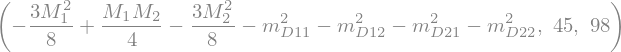

In [4]:
a_c, b_c, c_c, d_c = charpoly.all_coeffs()[1:]
p_c = sp.expand(b_c - sp.Rational(3, 8)*a_c**2)
q_c = sp.expand(c_c - a_c*b_c/2 + a_c**3/8)
r_c = sp.expand(d_c - a_c*c_c/4 + a_c**2*b_c/16 - sp.Rational(3, 256)*a_c**4)
p_c, sp.count_ops(q_c), sp.count_ops(r_c)

In [5]:
start = time.perf_counter()
direct = direct_diagonalization(seesaw)
U_direct = direct['U']
time_direct = time.perf_counter() - start
{'seconds': round(time_direct, 2),
 'size of each mass': [expression_size(mass) for mass in direct['masses']],
 'size of U': expression_size(U_direct)}

{'seconds': 0.24,
 'size of each mass': [{'tree': 2349, 'dag': 134},
  {'tree': 2349, 'dag': 134},
  {'tree': 2350, 'dag': 133},
  {'tree': 2350, 'dag': 133}],
 'size of U': {'tree': 508996, 'dag': 262}}

`expression_size` gives two numbers: `tree` is the size of the formula written out in full, `dag` the number of distinct subexpressions (the formula as a sequence of nested definitions $p,q,r\to\mu\to\lambda_i\to U$). The closed form exists and is exact (checked below). Written out, each mass has thousands of nodes and the mixing matrix hundreds of thousands to millions, so it cannot be read; as nested definitions it is only a few hundred steps, so it is perfectly usable for numerical evaluation.

In [6]:
heavy_ranges = {MR[i, i]: (4.0 + 3*i, 5.0 + 3*i) for i in range(2)}
verify_takagi(U_direct, Mnu, zeros + direct['masses'], n_points=3, ranges=heavy_ranges)

{'passed': True,
 'diagonalization_error': 1.274671495840511e-13,
 'unitarity_error': 4.5311840763625997e-13,
 'mass_error': 3.5199647724575767e-15,
 'n_points': 3,
 'precision': 'double'}

## 3. Semi-explicit form

Keeping the masses as symbols, subject to $p(\lambda_j)=0$ with $\lambda_j=-m_j$ (light) or $+m_j$ (heavy), the eigenvectors are the columns of $\mathrm{adj}(M-\lambda_j)$: polynomial in the parameters and $\lambda_j$.

In [7]:
semi = semi_explicit_diagonalization(seesaw)
U_semi = semi['U']
semi['eigenvalues'], expression_size(U_semi)

([-m_{n_1}, -m_{n_2}, m_{n_3}, m_{n_4}], {'tree': 1680, 'dag': 122})

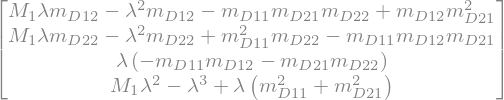

In [8]:
eigenvector_from_adjugate(Mnu, lamb).applyfunc(lambda x: sp.collect(sp.expand(x), lamb))

In [9]:
verify_takagi(U_semi, Mnu, zeros + massive, points=numeric_mass_points(seesaw, n_points=3))

{'passed': True,
 'diagonalization_error': 4.2242326988048575e-15,
 'unitarity_error': 1.2669604060822013e-14,
 'mass_error': 0.0,
 'n_points': 3,
 'precision': 'double'}

The modulus of each mixing element needs no eigenvector at all (eigenvector–eigenvalue identity):

$$|U_{ai}|^2=\frac{\det(\lambda_i-M_{(a)})}{\prod_{j\neq i}(\lambda_i-\lambda_j)} ,$$

with $M_{(a)}$ the matrix without row and column $a$. For the active component $a=1$ of the lightest massive state:

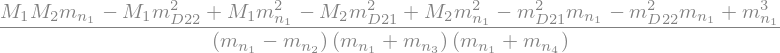

In [10]:
all_eigenvalues = zeros + semi['eigenvalues']
Ue_light = eigenvector_eigenvalue_identity(Mnu, all_eigenvalues, seesaw.n_massless, 0)
sp.factor(Ue_light)

In [11]:
point = numeric_mass_points(seesaw, n_points=1)[0]
float(Ue_light.subs(point)), float(abs(complex(U_semi[0, seesaw.n_massless].subs(point)))**2)

## 4. Inverse problem: exact Casas–Ibarra parametrization

Write the mixing matrix as

$$W=\begin{pmatrix}c_l & X^\dagger c_h\\ -Xc_l & c_h\end{pmatrix},\qquad c_l=(1+X^\dagger X)^{-1/2},\quad c_h=(1+XX^\dagger)^{-1/2}.$$

The vanishing of the active–active block of $M=W^*\,\mathrm{diag}(d,D)\,W^\dagger$ is equivalent to $d+X^TDX=0$, solved **exactly** by

$$X=i\,D^{-1/2}\,O\,d^{1/2},\qquad O^TO=1,$$

with $d$ and $D$ the light and heavy masses and $O$ the $2\times2$ rotation by an angle $\omega$. Then $m_D=c_l^*X^TD\,c_h^{-1}$ and $M_R=X^*c_l^*\,d\,c_lX^\dagger+c_h^*Dc_h$. The masses are inputs, so no quartic is solved; the only irrational step is the square root of a $2\times2$ matrix.

In [12]:
omega = symbols('omega', real=True)
angles = [omega]
O = orthogonal_matrix(2, [omega])
light = zeros + massive[:2]
heavy = massive[2:]
start = time.perf_counter()
exact = exact_seesaw_parametrization(light, heavy, O, real=True)
time_inverse = time.perf_counter() - start
exact['X'], round(time_inverse, 2), expression_size(exact['M'])

(Matrix([
 [I*sqrt(m_{n_1})*cos(omega)/sqrt(m_{n_3}), -I*sqrt(m_{n_2})*sin(omega)/sqrt(m_{n_3})],
 [I*sqrt(m_{n_1})*sin(omega)/sqrt(m_{n_4}),  I*sqrt(m_{n_2})*cos(omega)/sqrt(m_{n_4})]]),
 0.17,
 {'tree': 251341, 'dag': 224})

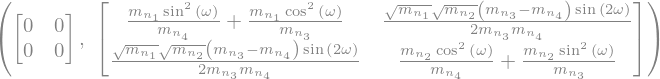

In [13]:
exact['M'][:2, :2], (exact['X'].H*exact['X']).applyfunc(simplify)

In [14]:
mass_ranges = {symbol: (0.05 + 0.1*i, 0.1 + 0.1*i) for i, symbol in enumerate(massive[:2])}
mass_ranges.update({symbol: (2.0 + i, 2.5 + i) for i, symbol in enumerate(heavy)})
verify_takagi(exact['U'], exact['M'], light + heavy, n_points=3, ranges=mass_ranges)

{'passed': True,
 'diagonalization_error': 5.655184532288808e-16,
 'unitarity_error': 4.440892098500626e-16,
 'mass_error': 4.628579995330904e-16,
 'n_points': 3,
 'precision': 'double'}

`exact['m_D']` is real for real $O$, and $M_R$ comes out in a general (non-diagonal) sterile basis. Parameter counting in that basis: $m_D$ (4) + $M_R$ (3) = 7 parameters $\leftrightarrow$ 4 masses + 1 angle(s) in $O$ + the active rotation(s) + the unphysical sterile rotation(s).

To leading order in $d/D$ one has $c_l,c_h\to1$ and $m_D\simeq X^TD=i\,d^{1/2}O^TD^{1/2}$, the usual Casas–Ibarra formula:

In [15]:
epsilon = symbols('epsilon', positive=True)
point = {**{symbol: 0.1*(i + 1) for i, symbol in enumerate(massive[:2])},
         **{symbol: 2.0 + i for i, symbol in enumerate(heavy)},
         **{angle: 0.4 + 0.3*i for i, angle in enumerate(angles)}}
mD_exact = np.array(exact['m_D'].subs(point).evalf(), dtype=complex)
mD_leading = np.array((-I*exact['X'].T*sp.diag(*heavy)).subs(point).evalf(), dtype=complex)
np.round(mD_exact.real, 4), np.round(mD_leading.real, 4)

(array([[ 0.4114,  0.2147],
        [-0.2479,  0.7126]]),
 array([[ 0.4119,  0.2133],
        [-0.2463,  0.7135]]))

## 5. Complex case: 2 physical phase(s)

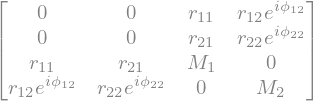

In [16]:
seesaw_c = SymbolicSeesawTypeI(n_generations=2, n_sterile=2, dirac='polar', majorana_basis='diagonal')
Mnu_c = seesaw_c.full_mass_matrix_symbolic()
Mnu_c

The squared masses are roots of the quartic $\det(\lambda-M^\dagger M)$ and the Takagi vectors are eigenvectors of $M^\dagger M$ normalized by $u_i^TMu_i=m_i$. The attempts below run in a subprocess with a time limit:

In [17]:
import pandas as pd
probes = [feasibility_probe(2, 2, 'complex', method, timeout=240)
          for method in ('direct', 'semi_explicit', 'inverse')]
pd.DataFrame(probes)[['method', 'degree', 'status', 'seconds', 'size', 'dag_size', 'verified']]

,method,degree,status,seconds,size,dag_size,verified
0,direct,4,ok,1.797097,61152462,545,True
1,semi_explicit,4,ok,1.336943,58788,376,True
2,inverse,4,ok,0.293556,323822,254,True


All three routes succeed. The direct result is enormous when written out (`size`) but short as nested definitions (`dag_size`); because of cancellations between nested radicals its numerical check is done with 50-digit arithmetic, which `verify_takagi` switches to automatically when double precision is not enough.

The inverse parametrization carries over unchanged with complex angles in $O$ (still $O^TO=1$), whose imaginary parts encode CP violation:

In [18]:
z = symbols('z')
O_c = orthogonal_matrix(2, [z])
exact_c = exact_seesaw_parametrization(light, heavy, O_c)
verify_takagi(exact_c['U'], exact_c['M'], light + heavy, n_points=3, ranges=mass_ranges)

{'passed': True,
 'diagonalization_error': 1.6381732556848414e-16,
 'unitarity_error': 4.440892098500626e-16,
 'mass_error': 7.2765253039859755e-16,
 'n_points': 3,
 'precision': 'double'}

## 6. Seesaw expansion

$m_\nu=-m_DM_R^{-1}m_D^T+\dots$ has rank $\min(n,m)=2$. The light masses from the expansion are compared with the exact ones; the relative error falls as $\epsilon^2$ and $\epsilon^4$.

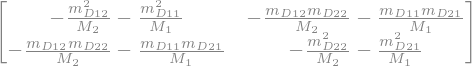

In [19]:
expansion = {order: seesaw_block_expansion(mD, MR, order=order) for order in (2, 4)}
expansion[2]['m_light']

In [20]:
parameters = list(mD) + [MR[i, i] for i in range(2)]
light_matrix = {order: sp.lambdify(parameters, expansion[order]['m_light'], 'numpy') for order in expansion}
full_matrix = sp.lambdify(parameters, Mnu, 'numpy')
rng = np.random.default_rng(1)
direction = rng.uniform(0.5, 1.5, size=len(list(mD)))
majorana_values = [1.0 + 1.5*i for i in range(2)]
rows = []
for eps in (0.2, 0.1, 0.05):
    values = list(eps*direction) + majorana_values
    exact_masses, _ = takagi_factorization(np.array(full_matrix(*values), dtype=complex))
    exact_light = exact_masses[seesaw.n_massless:seesaw.n_massless + 2]
    row = {'epsilon': eps}
    for order in expansion:
        approx, _ = takagi_factorization(np.array(light_matrix[order](*values), dtype=complex))
        row[f'max rel. error O(eps^{order})'] = np.max(np.abs(approx[seesaw.n_massless:]/exact_light - 1))
    rows.append(row)
pd.DataFrame(rows)

,epsilon,max rel. error O(eps^2),max rel. error O(eps^4)
0,0.20,0.076370,0.013376
1,0.10,0.020349,0.000921
2,0.05,0.005179,0.000059


## Summary

| method | real case | complex case |
|:--|:--|:--|
| direct (Ferrari quartic) | exact and verified; $\sim10^5$–$10^6$ nodes written out, a few hundred as nested definitions | exact and verified (50 digits); $\gtrsim10^7$ nodes written out |
| semi-explicit (masses as symbols) | compact, verified | compact, verified |
| inverse (exact Casas–Ibarra) | closed form, verified | closed form with complex $O$, verified |
| seesaw expansion | any order | any order |

With four massive states this is the largest problem whose masses can be written in radicals. Adding one more massive state gives a quintic: see `seesaw_3_active_3_sterile.ipynb`.